# GMTOA through the PDV and AMV cycle (CESM2 piControl)

Effective sample size after Metz (1991) as in Miyamoto et al. (2026), 90 % level, and stippling on the maps with field significance after Wilks (2016). 



| Label | Index from | TOA from | Meaning |
|---|---|---|---|
| lag −3 yr | year t | year t − 3 | TOA three years **before** (TOA comes first) |
| lag 0 yr | year t | year t | same year |
| lag +3 yr | year t | year t + 3 | TOA three years **after** (the index comes first) |


**Units.** TOA is downward positive (positive = planet gains energy). Regressions are in W m⁻² per 1σ of the decadal index (or of its rate of change).


1. **Input:** the annual anomalies and the PDV/AMV indices come from `01_piControl_annual_anomalies.ipynb` (run it first). No raw CESM2 file is read here.
2. **Results on disk:** the lead-lag curves, the lag regression maps and the rate-of-change maps of section 6 are written to `results_dir` (`data/piControl/lanczos/`) with the settings they depend on, together with the filtered indices and GMTOA. The next run reads them back; set `recompute = True` after changing `lags`, `L_metz`, the filter or `ci_percent`. 

In [21]:
import pathlib
import warnings

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from xarray import SerializationWarning

import functions as fv
from functions import (
    area_weights,
    transition,
)

warnings.filterwarnings('ignore', category=SerializationWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='invalid value encountered in create_collection')

## 1 Config

In [ ]:
# --- data: annual anomalies (first 100 years dropped, linear trend removed) and the
# PDV/AMV indices, all written by 01_piControl_annual_anomalies.ipynb ---
anom_dir = pathlib.Path('/path/to/data')  # change to your data directory
index_file = anom_dir / 'PDV_AMV_annual.nc'

# --- results of this notebook: computed once, written here, read back on the next run ---
results_dir = pathlib.Path('/path/to/data/piControl/lanczos')  # change to your output directory
recompute = False        # True: compute again and overwrite (e.g. after changing lags or L_metz)

# --- decadal filter: Lanczos low-pass on annual means ---
cutoff_years = 10
window = 41              # number of weights; (window - 1) / 2 years are lost at each end

# --- lags in whole years, used for the curve and the maps; has to contain 0 ---
# negative = TOA before year 0, positive = TOA after it
lags = list(range(-8, 9))

# --- composites ---
threshold = 1.0          # in std of the index (state) or of its rate of change (transition)

# --- uncertainty (t-test) ---
ci_percent = 90          # as in Miyamoto et al. (2026)
L_metz = 50              # longest lag (years) in the autocorrelation sum of Metz (1991)

# --- significance on the maps ---
stippling = True         # stipple the grid points that pass the test
use_fdr = True           # True: field significance (FDR, Wilks 2016); False: local test only
alpha_fdr = 0.10         
stipple_step = 4         # a dot on every n-th grid point (lat and lon); larger = fewer dots
stipple_size = 1.5       # dot size (points squared)
stipple_color = '0.25'   # grey: 0 = black, 1 = white

# --- figures ---
map_levels = np.linspace(-3, 3, 21)   
toa_cmap = 'bwr'         
lat_limit = None         # crop the maps to ±lat_limit degrees (60 as in the storyline maps); None = whole globe
save_figures = False     # True writes every figure to figure_path(<name>)

## 2 Helpers

The helpers (filter, Metz test, regression, FDR, maps, results on disk) are in `functions.py`. The cell below passes them the settings of the config cell, so the rest of the notebook calls them as before and the config cell stays the only place to edit.

In [3]:
# helpers from functions.py that need no setting
from functions import (
    global_mean, standardise, lag_label, acf, lagged_regression, count_events,
    composite_pvalues, stack,
)

# equal-area, as in the storyline composites
map_projection = ccrs.EqualEarth(central_longitude=180)


# ---- the helpers that use settings of the config cell ----

def lanczos_lowpass(da, dim='time'):
    return fv.lanczos_lowpass(da, cutoff_years, window, dim)


def stipple_mask(p):
    return fv.stipple_mask(p, use_fdr, alpha_fdr, ci_percent)


def finish(fig, name):
    fv.finish(fig, name, save_figures)


def read_anom(name):
    return fv.read_anom(name, anom_dir)


def load_result(name):
    return fv.load_result(name, results_dir, result_settings(), recompute)


def lagged_curve(y, x, lags):
    return fv.lagged_curve(y, x, lags, L_metz, ci_percent)


def composite_mean_ci(y, selected):
    return fv.composite_mean_ci(y, selected, ci_percent)


def regression_pvalues(field, index, lag, L=None, acf_field=None):
    return fv.regression_pvalues(field, index, lag, L_metz if L is None else L, acf_field)


def plot_map(ax, da, title, fontsize=10, sig=None, step=None, label='GMTOA '):
    """TOA map with map_levels and toa_cmap; the global mean behind ``label`` in the corner."""
    return fv.plot_map(ax, da, title, map_levels, toa_cmap, fontsize=fontsize, sig=sig,
                       step=stipple_step if step is None else step, stipple_size=stipple_size,
                       stipple_color=stipple_color, lat_limit=lat_limit, label=label)


# results on disk: settings the stored results depend on
def result_settings():
    return dict(cutoff_years=cutoff_years, window=window, lags=str(list(lags)),
                L_metz=L_metz, ci_percent=ci_percent)


def save_result(ds, name):
    fv.save_result(ds, name, results_dir, result_settings(), '04_piControl_state_transition.ipynb')

## 3 Data and indices

Same preprocessing for everything: annual mean → drop the first 100 years → remove the linear trend → 10-yr Lanczos low-pass.

The PDV and AMV indices are read from `PDV_AMV_annual.nc` (written by `01_piControl_annual_anomalies.ipynb`), one value per year as the lag analysis needs; only the filter is applied here. Their decade means define the storylines in `02_piControl_decadal_storylines.ipynb`.

In [4]:
time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)

In [5]:
# TOA, all downward positive: SW = absorbed solar (rsdt - rsut), LW = -OLR, net = SW + LW
sw_anom = read_anom('SWTOA')
lw_anom = read_anom('LWTOA')

sw_dec = lanczos_lowpass(sw_anom)
lw_dec = lanczos_lowpass(lw_anom)

# decadal TOA net field, as anomaly from its own time mean
toa_dec = sw_dec + lw_dec
toa_dec = toa_dec - toa_dec.mean('time')

# global means; every step above is linear, so net = SW + LW holds exactly
gm = xr.Dataset({
    'net': global_mean(toa_dec),
    'SW': global_mean(sw_dec),
    'LW': global_mean(lw_dec),
})
gm = gm - gm.mean('time')

del sw_anom, lw_anom, sw_dec, lw_dec
print(f"decadal record: {toa_dec.sizes['time']} years")
print(f"std of decadal GMTOA: {float(gm['net'].std()):.3f} W m-2")

decadal record: 1060 years
std of decadal GMTOA: 0.129 W m-2


In [6]:
# Indices from 01_piControl_annual_anomalies.ipynb. They are already annual anomalies
# (first 100 years dropped, detrended), so only the filter is applied here.
indices = xr.open_dataset(index_file, decode_times=time_coder)
pdv = lanczos_lowpass(indices['PDV'].load()).rename('PDV')
amv = lanczos_lowpass(indices['AMV'].load()).rename('AMV')

# rate of change of the decadal index (centred difference, per year)
pdv_rate = transition(pdv).rename('PDV_rate')
amv_rate = transition(amv).rename('AMV_rate')

# stops here if the indices and the TOA field are not on the same years
xr.align(pdv, amv, gm, toa_dec, join='exact')

# mode name -> (index for the state, rate of change for the transition);
# used by every section below
modes = {'PDV': (pdv, pdv_rate), 'AMV': (amv, amv_rate)}

# filtered indices, their rates of change and GMTOA, for the figure notebooks
save_result(xr.Dataset({
    'PDV': pdv, 'AMV': amv, 'PDV_rate': pdv_rate, 'AMV_rate': amv_rate,
    'GMTOA_net': gm['net'], 'GMTOA_SW': gm['SW'], 'GMTOA_LW': gm['LW'],
}), 'gmtoa_indices_lanczos')

wrote /Users/liobabraun/Desktop/Uni_Leipzig/MA/server/data/piControl/lanczos/gmtoa_indices_lanczos.nc


**Index correlations**

In [7]:
def corr(a, b):
    return float(np.corrcoef(a.values, b.values)[0, 1])

print(f'r(PDV, AMV)         = {corr(pdv, amv):+.2f}')
print(f'r(PDV, dPDV/dt)     = {corr(pdv, pdv_rate):+.2f}')
print(f'r(AMV, dAMV/dt)     = {corr(amv, amv_rate):+.2f}')
print(f'r(dPDV/dt, dAMV/dt) = {corr(pdv_rate, amv_rate):+.2f}')

r(PDV, AMV)         = -0.27
r(PDV, dPDV/dt)     = -0.00
r(AMV, dAMV/dt)     = +0.01
r(dPDV/dt, dAMV/dt) = -0.39


## 4 Lead-lag GMTOA

GMTOA regressed on the index (**state**) and on its rate of change (**transition**), with the TOA value taken from 8 years before to 8 years after the index year.

For PDV and AMV
Left of zero: GMTOA in the years *before* the index year. Right of zero: GMTOA in the years *after* it.

read /Users/liobabraun/Desktop/Uni_Leipzig/MA/server/data/piControl/lanczos/gmtoa_leadlag_curves.nc


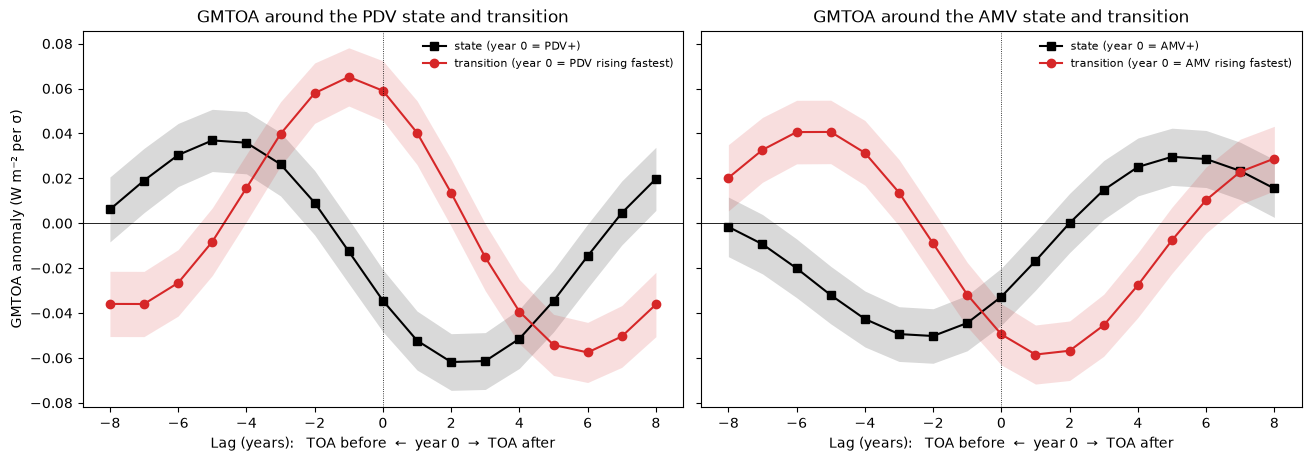

PDV state       at lag 0 yr: -0.034   highest: +0.037 at lag -5 yr   lowest: -0.062 at lag +2 yr   effective sample size: 222 of 1060 years
PDV transition  at lag 0 yr: +0.059   highest: +0.065 at lag -1 yr   lowest: -0.058 at lag +6 yr   effective sample size: 204 of 1060 years
AMV state       at lag 0 yr: -0.033   highest: +0.030 at lag +5 yr   lowest: -0.050 at lag -2 yr   effective sample size: 263 of 1060 years
AMV transition  at lag 0 yr: -0.050   highest: +0.041 at lag -5 yr   lowest: -0.058 at lag +1 yr   effective sample size: 210 of 1060 years


In [8]:
# lead-lag curves of GMTOA: read back if written before, else computed and written
saved = load_result('gmtoa_leadlag_curves')
if saved is None:
    curves = {
        mode: {
            'state': lagged_curve(gm['net'], level, lags),
            'transition': lagged_curve(gm['net'], rate, lags),
        }
        for mode, (level, rate) in modes.items()
    }
    table = pd.concat({(m, k): c for m, pair in curves.items() for k, c in pair.items()},
                      names=['mode', 'kind'])
    save_result(xr.Dataset.from_dataframe(table), 'gmtoa_leadlag_curves')
else:
    curves = {m: {k: saved.sel(mode=m, kind=k).to_dataframe()[['slope', 'low', 'high', 'n_eff']]
                  for k in ('state', 'transition')}
              for m in modes}

curve_style = {'state': ('black', 's'), 'transition': ('tab:red', 'o')}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True, constrained_layout=True)
for ax, (mode, pair) in zip(axes, curves.items()):
    for kind, curve in pair.items():
        color, marker = curve_style[kind]
        marked = f'{mode}+' if kind == 'state' else f'{mode} rising fastest'
        ax.fill_between(curve.index, curve['low'], curve['high'], color=color, alpha=0.15, lw=0)
        ax.plot(curve.index, curve['slope'], color=color, marker=marker,
                label=f'{kind} (year 0 = {marked})')
    ax.axhline(0, color='black', lw=0.6)
    ax.axvline(0, color='black', lw=0.6, ls=':')
    ax.set_xlabel('Lag (years):   TOA before  ←  year 0  →  TOA after')
    ax.set_title(f'GMTOA around the {mode} state and transition')
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel('GMTOA anomaly (W m⁻² per σ)')
finish(fig, 'GMTOA_cycle_leadlag')

n_years = pdv.sizes['time']
for mode, pair in curves.items():
    for kind, curve in pair.items():
        slope = curve['slope']
        print(f"{mode} {kind:10s}  at {lag_label(0)}: {slope.loc[0]:+.3f}   "
              f"highest: {slope.max():+.3f} at {lag_label(slope.idxmax())}   "
              f"lowest: {slope.min():+.3f} at {lag_label(slope.idxmin())}   "
              f"effective sample size: {curve.loc[0, 'n_eff']:.0f} of {n_years} years")

In [9]:
# lag regression maps and their p-values: read back if written before, else computed
# in the next cell
saved_maps = load_result('gmtoa_lag_regression_maps')

# what "year 0" is for each kind of regression
year_zero = {
    'state': 'year 0 = {mode}+',
    'transition': 'year 0 = fastest {mode} rise',
}


def scale_check(name, maps):
    """Print the 99th percentile |value| of the maps of one figure, next to map_levels.

    Only a print: the levels are set by hand in the config. With extend='both' a
    scale that is too tight clips silently, one that is too wide makes weak maps pale.
    """
    peak = max(float(np.nanpercentile(np.abs(da.values), 99)) for da in maps)
    print(f'{name}: 99th percentile |value| = {peak:.2f} W m-2, '
          f'map_levels reach {map_levels[-1]:.2f}')

read /Users/liobabraun/Desktop/Uni_Leipzig/MA/server/data/piControl/lanczos/gmtoa_lag_regression_maps.nc


In [10]:
# float32 copy of the field, also used by the composites in section 5
toa32 = toa_dec.transpose('time', 'lat', 'lon').astype('float32')
kinds = ('state', 'transition')

if saved_maps is None:
    reg_maps = {
        mode: {
            'state': lagged_regression(toa_dec, level, lags),
            'transition': lagged_regression(toa_dec, rate, lags),
        }
        for mode, (level, rate) in modes.items()
    }
    # autocorrelation of the field, computed once; p-values for every (mode, kind, lag)
    toa_acf = acf(toa32.values, L_metz)
    reg_pvalues = {
        (mode, kind, lag): regression_pvalues(toa32, index, lag, acf_field=toa_acf)
        for mode, pair in modes.items()
        for kind, index in zip(kinds, pair)
        for lag in lags
    }
    out = xr.Dataset({
        'coef': stack({m: stack(reg_maps[m], 'kind') for m in modes}, 'mode').astype('float32'),
        'p': stack({m: stack({k: stack({lag: reg_pvalues[m, k, lag] for lag in lags}, 'lag')
                              for k in kinds}, 'kind') for m in modes}, 'mode'),
    })
    save_result(out, 'gmtoa_lag_regression_maps')
else:
    reg_maps = {m: {k: saved_maps['coef'].sel(mode=m, kind=k, drop=True) for k in kinds}
                for m in modes}
    reg_pvalues = {(m, k, lag): saved_maps['p'].sel(mode=m, kind=k, lag=lag, drop=True)
                   for m in modes for k in kinds for lag in lags}

reg_sig = {key: stipple_mask(p) for key, p in reg_pvalues.items()} if stippling else {}

**Coefficient maps**

PDV state, lag 0 yr: 99th percentile |value| = 2.33 W m-2, map_levels reach 3.00
PDV transition, lag 0 yr: 99th percentile |value| = 0.65 W m-2, map_levels reach 3.00
AMV state, lag 0 yr: 99th percentile |value| = 1.04 W m-2, map_levels reach 3.00
AMV transition, lag 0 yr: 99th percentile |value| = 0.77 W m-2, map_levels reach 3.00


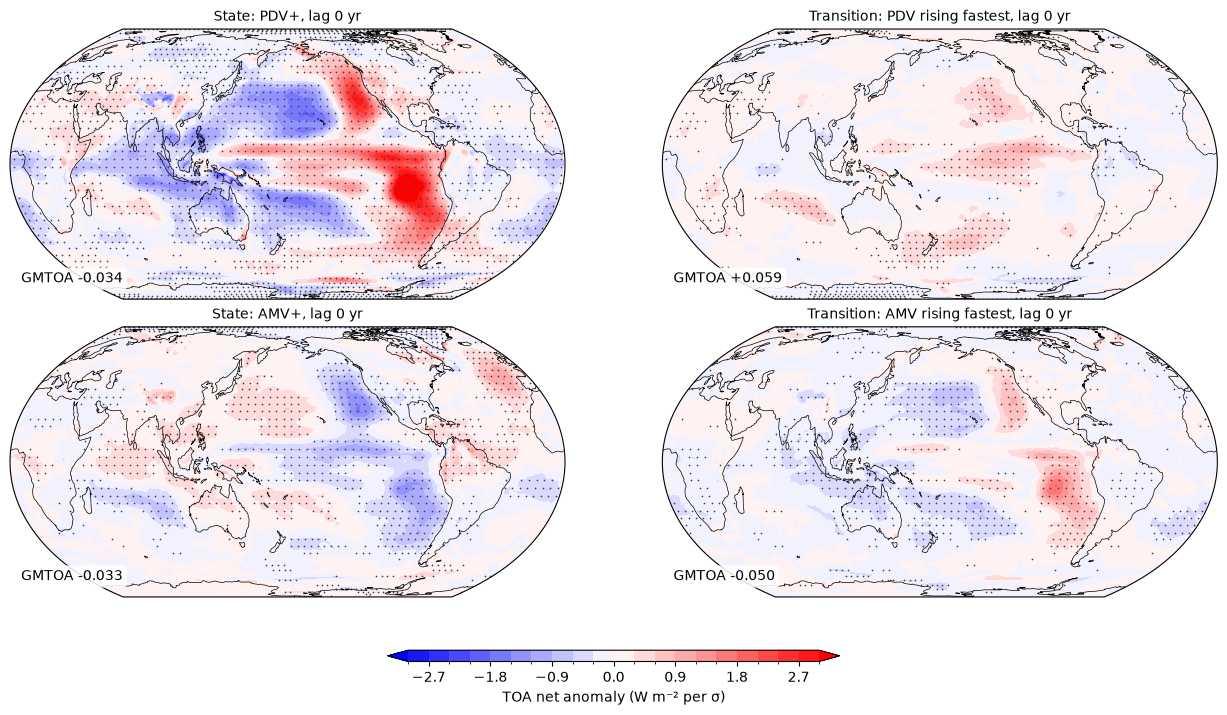

In [22]:
for mode in reg_maps:
    for kind in ('state', 'transition'):
        scale_check(f'{mode} {kind}, {lag_label(0)}', [reg_maps[mode][kind].sel(lag=0)])

fig, axes = plt.subplots(
    2, 2, figsize=(13, 7), subplot_kw={'projection': map_projection}, constrained_layout=True,
)
for row, mode in zip(axes, reg_maps):
    plot_map(row[0], reg_maps[mode]['state'].sel(lag=0), f'State: {mode}+, {lag_label(0)}',
             sig=reg_sig.get((mode, 'state', 0)))
    im = plot_map(row[1], reg_maps[mode]['transition'].sel(lag=0),
                  f'Transition: {mode} rising fastest, {lag_label(0)}',
                  sig=reg_sig.get((mode, 'transition', 0)))
cbar = fig.colorbar(im, ax=axes, orientation='horizontal', shrink=0.35, aspect=40, pad=0.08)
cbar.set_label('TOA net anomaly (W m⁻² per σ)')
finish(fig, 'GMTOA_cycle_state_vs_transition')

**Regression of GMTOA and net TOA radiation onto PDV state and transition**

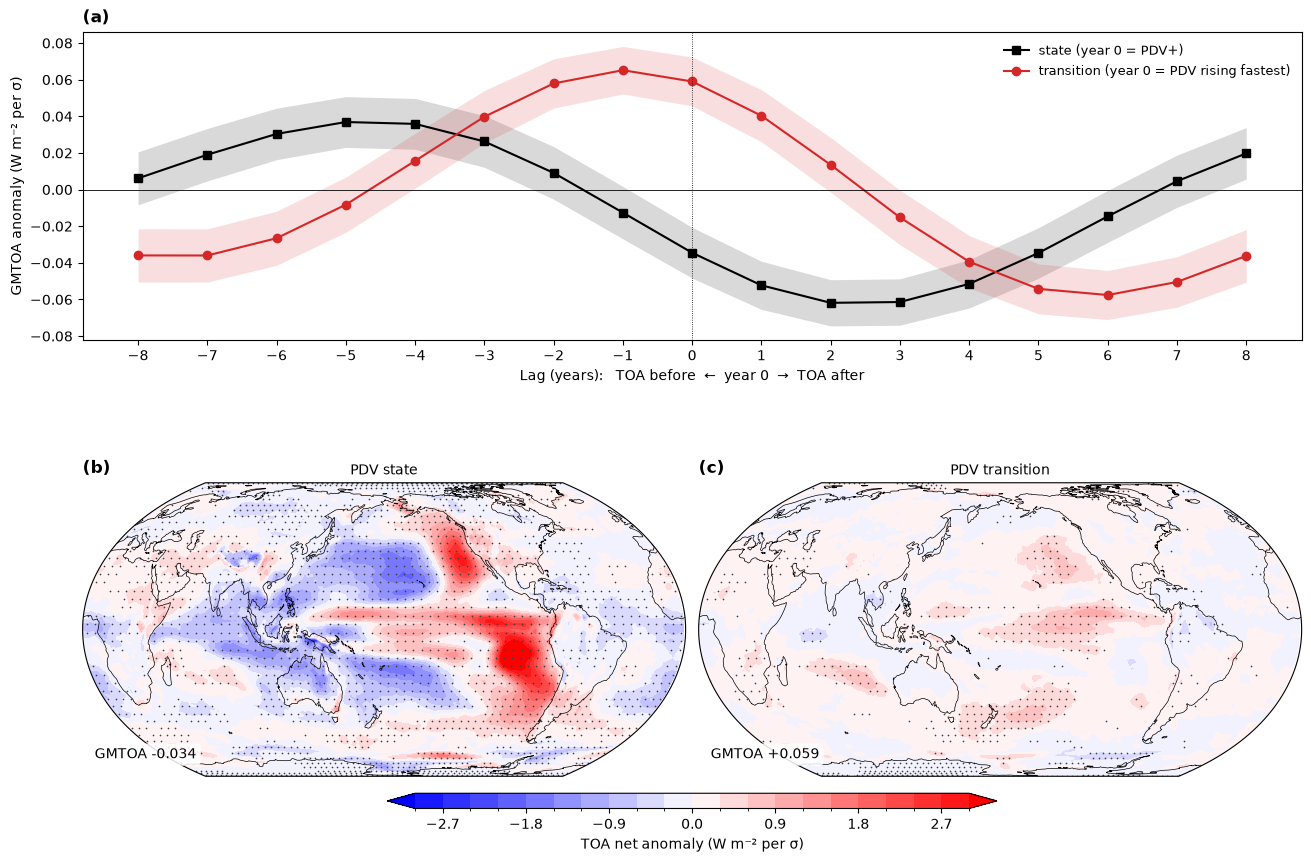

sigma PDV state:      0.369 K
sigma PDV transition: 0.124 K/yr


In [23]:
# Summary figure, PDV only: (a) lag curve of GMTOA, (b) state map and (c) transition map
# at lag 0. Reuses curves (section 4), reg_maps and reg_sig (above); nothing is recomputed.
fig = plt.figure(figsize=(13, 8.5), constrained_layout=True)
grid = fig.add_gridspec(2, 2, height_ratios=[0.8, 1])
ax_a = fig.add_subplot(grid[0, :])
ax_b = fig.add_subplot(grid[1, 0], projection=map_projection)
ax_c = fig.add_subplot(grid[1, 1], projection=map_projection)

# (a) same curves, colours and 90 % band as the lag-curve figure of section 4
for kind, curve in curves['PDV'].items():
    color, marker = curve_style[kind]
    marked = 'PDV+' if kind == 'state' else 'PDV rising fastest'
    ax_a.fill_between(curve.index, curve['low'], curve['high'], color=color, alpha=0.15, lw=0)
    ax_a.plot(curve.index, curve['slope'], color=color, marker=marker,
              label=f'{kind} (year 0 = {marked})')
ax_a.axhline(0, color='black', lw=0.6)
ax_a.axvline(0, color='black', lw=0.6, ls=':')
ax_a.set_xticks(lags)
ax_a.set_xlabel('Lag (years):   TOA before  ←  year 0  →  TOA after')
ax_a.set_ylabel('GMTOA anomaly (W m⁻² per σ)')
ax_a.legend(frameon=False, fontsize=9)

# (b), (c) same scale, projection, stippling and GMTOA label as the maps above
plot_map(ax_b, reg_maps['PDV']['state'].sel(lag=0), 'PDV state',
         sig=reg_sig.get(('PDV', 'state', 0)))
im = plot_map(ax_c, reg_maps['PDV']['transition'].sel(lag=0), 'PDV transition',
              sig=reg_sig.get(('PDV', 'transition', 0)))
cbar = fig.colorbar(im, ax=[ax_b, ax_c], orientation='horizontal', shrink=0.5, aspect=40, pad=0.04)
cbar.set_label('TOA net anomaly (W m⁻² per σ)')

for ax, letter in zip((ax_a, ax_b, ax_c), 'abc'):
    ax.text(0.0, 1.02, f'({letter})', transform=ax.transAxes,
            fontsize=12, fontweight='bold', va='bottom', ha='left')

finish(fig, 'GMTOA_cycle_PDV_summary')

# for the caption: std of the filtered, not standardised series
print(f'sigma PDV state:      {float(pdv.std()):.3f} K')
print(f'sigma PDV transition: {float(pdv_rate.std()):.3f} K/yr')

**Lead-lag regression maps**

PDV state, all lags: 99th percentile |value| = 2.33 W m-2, map_levels reach 3.00


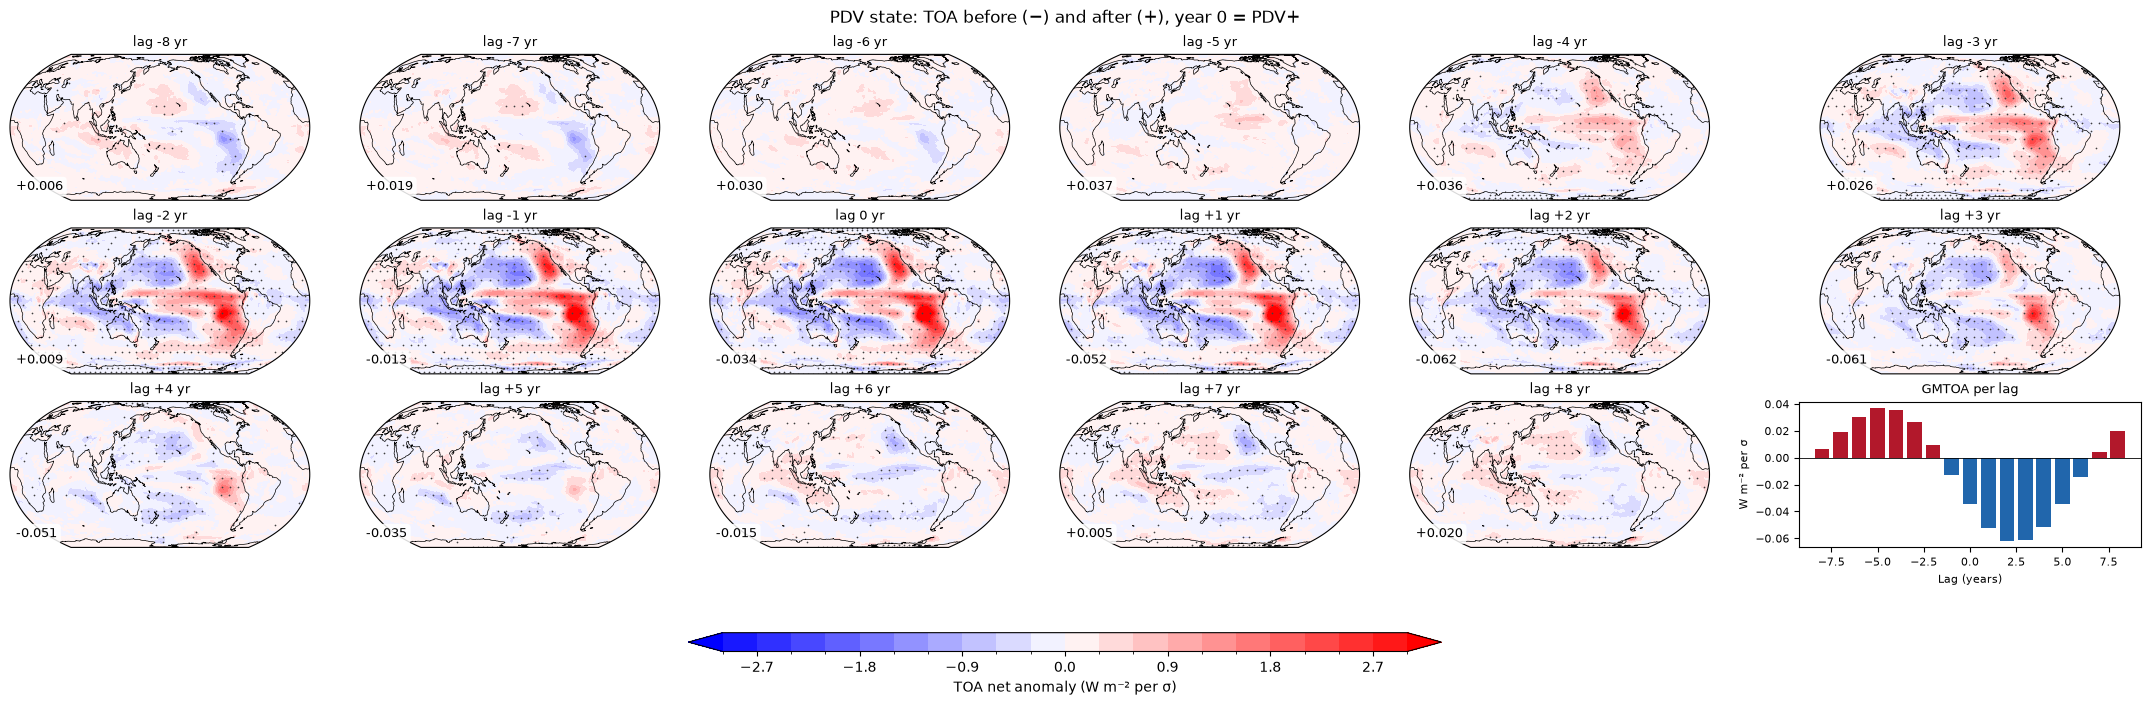

PDV transition, all lags: 99th percentile |value| = 1.80 W m-2, map_levels reach 3.00


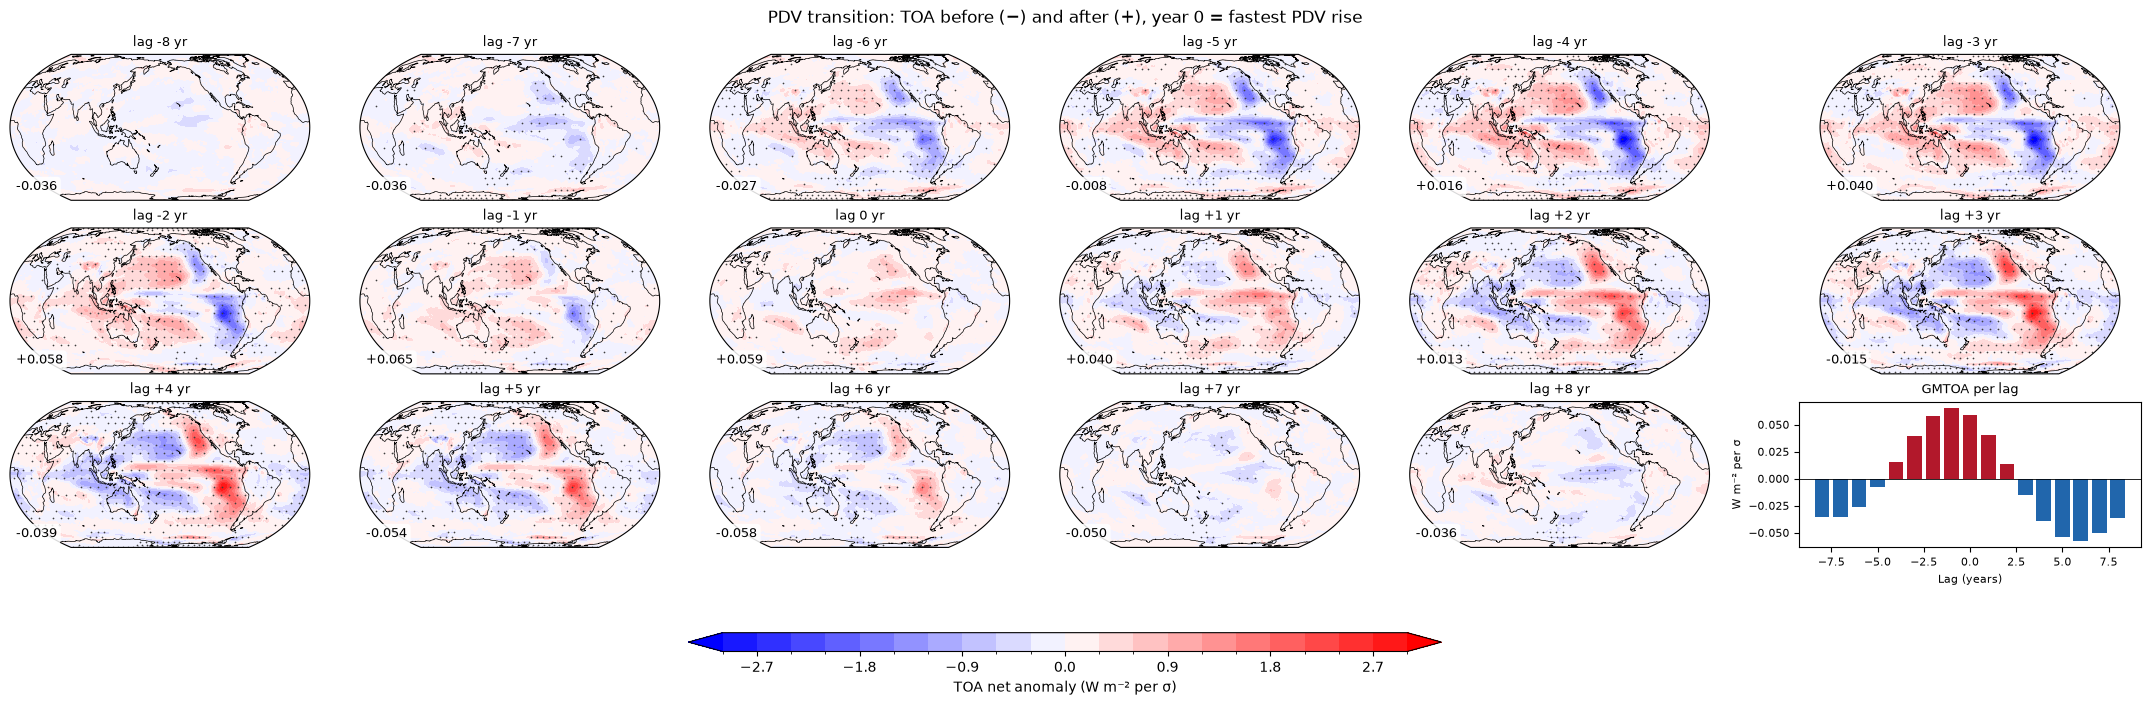

AMV state, all lags: 99th percentile |value| = 1.14 W m-2, map_levels reach 3.00


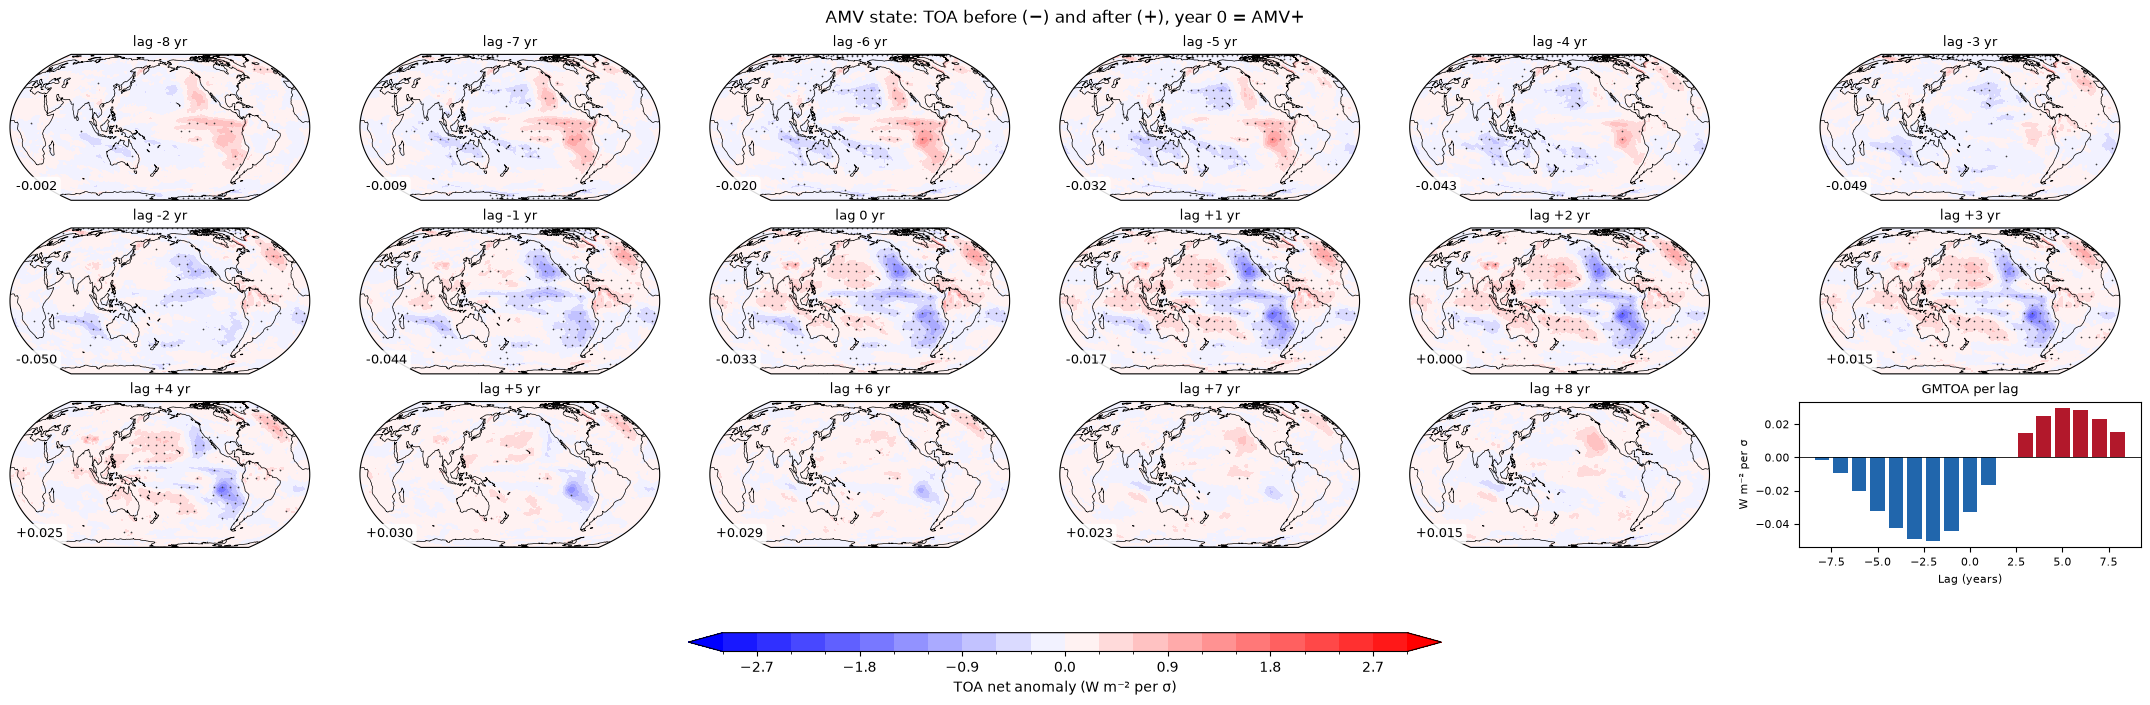

AMV transition, all lags: 99th percentile |value| = 1.28 W m-2, map_levels reach 3.00


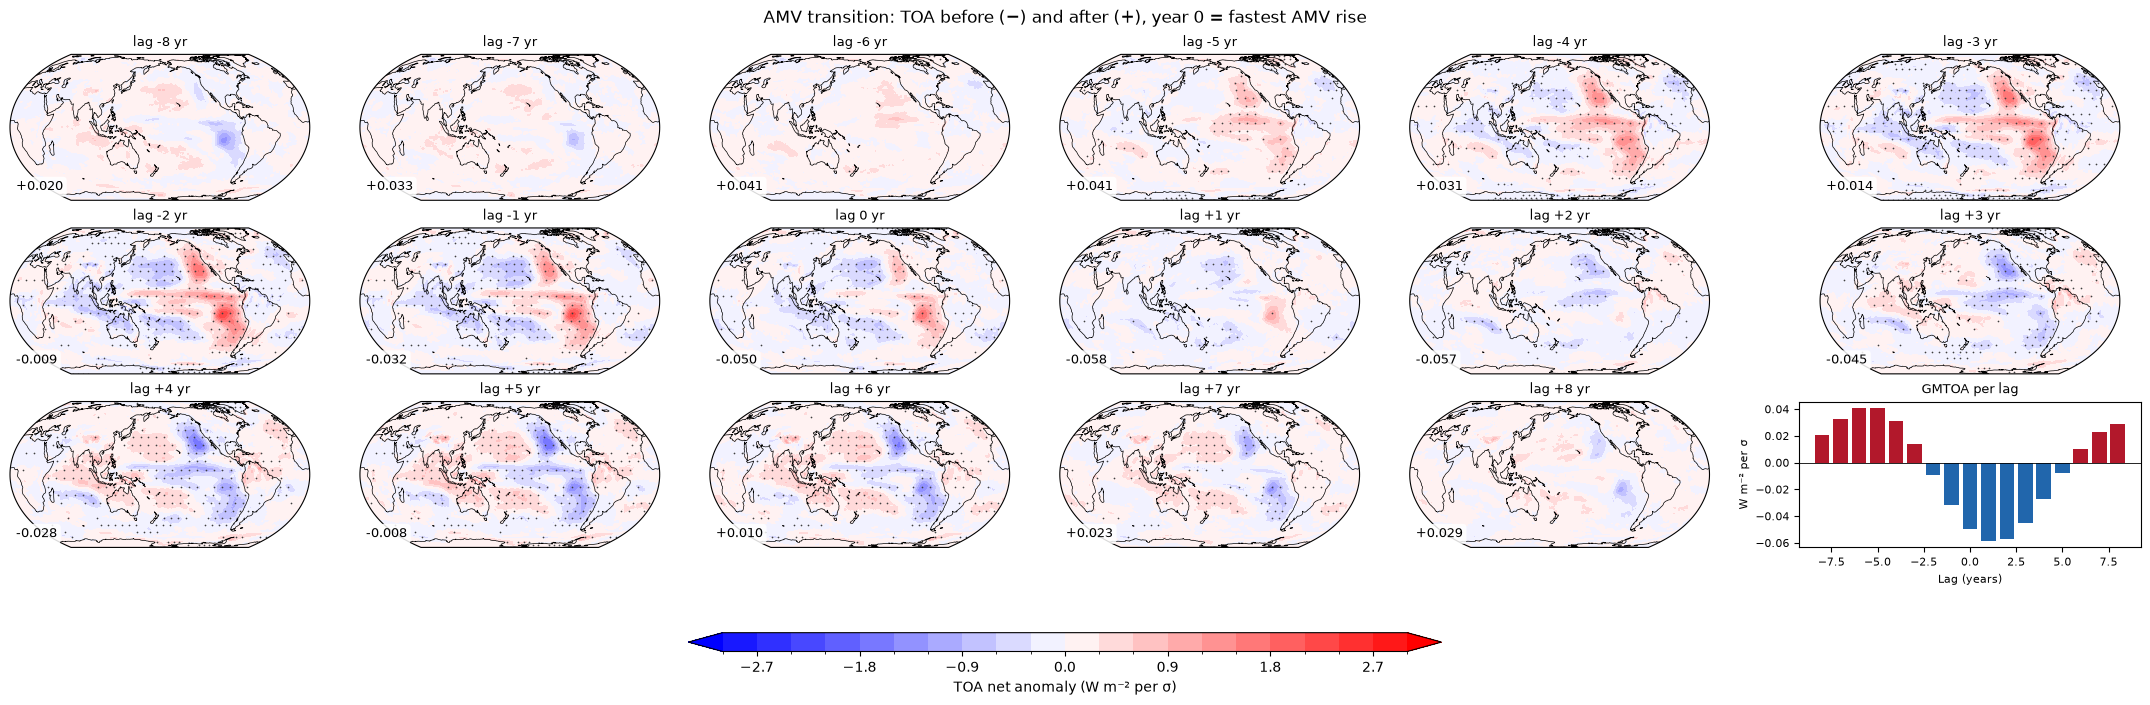

In [24]:
n_cols = 6
n_rows = int(np.ceil(len(lags) / n_cols))

for mode, pair in reg_maps.items():
    for kind, maps in pair.items():
        scale_check(f'{mode} {kind}, all lags', [maps.sel(lag=lag) for lag in lags])

        fig, axes = plt.subplots(
            n_rows, n_cols, figsize=(3.6 * n_cols, 2.3 * n_rows),
            subplot_kw={'projection': map_projection}, constrained_layout=True,
        )
        map_axes = list(axes.flat[:len(lags)])
        for ax, lag in zip(map_axes, lags):
            # small panels: half as many dots as in the large maps, number without label
            im = plot_map(ax, maps.sel(lag=lag), lag_label(lag), fontsize=9,
                          sig=reg_sig.get((mode, kind, lag)), step=2 * stipple_step, label='')

        # the panels left over: one becomes a bar plot of the global means
        spare = list(axes.flat[len(lags):])
        for ax in spare:
            ax.remove()
        if spare:
            values = np.array([float(global_mean(maps.sel(lag=lag))) for lag in lags])
            bar_ax = fig.add_subplot(n_rows, n_cols, len(lags) + 1)
            bar_ax.bar(lags, values, color=np.where(values >= 0, '#b2182b', '#2166ac'))
            bar_ax.axhline(0, color='black', lw=0.6)
            bar_ax.set_title('GMTOA per lag', fontsize=9)
            bar_ax.set_xlabel('Lag (years)', fontsize=8)
            bar_ax.set_ylabel('W m⁻² per σ', fontsize=8)
            bar_ax.tick_params(labelsize=8)

        cbar = fig.colorbar(im, ax=map_axes, orientation='horizontal', shrink=0.35, aspect=40, pad=0.08)
        cbar.set_label('TOA net anomaly (W m⁻² per σ)')
        fig.suptitle(f'{mode} {kind}: TOA before (−) and after (+), '
                     + year_zero[kind].format(mode=mode))
        finish(fig, f'GMTOA_cycle_lagmaps_{mode}_{kind}')

## 5 State and transition composites 

A check on section 4 with composites instead of regressions: the numbers are in W m⁻² instead of per σ, and the asymmetry rows (high + low, rising + falling) show whether the two signs really are mirror images. 

`years` is the number of years averaged. `events` is the number of separate runs of consecutive years. The 90 % interval for `net` (`net low` to `net high`) comes from a t-test in which every event counts once, not every year.

In [14]:
def composite_cases(level, rate):
    level_std, rate_std = standardise(level).values, standardise(rate).values
    return {
        'state high': level_std > threshold,
        'state low': level_std < -threshold,
        'transition rising': rate_std > threshold,
        'transition falling': rate_std < -threshold,
    }


def composite_table(cases):
    rows = {}
    for name, selected in cases.items():
        net, low, high = composite_mean_ci(gm['net'].values, selected)
        rows[name] = {
            'years': int(selected.sum()),
            'events': count_events(selected),
            'net': net, 'net low': low, 'net high': high,
            'SW': gm['SW'].values[selected].mean(),
            'LW': gm['LW'].values[selected].mean(),
        }
    table = pd.DataFrame(rows).T
    for label, (a, b) in {'state asymmetry (high + low)': ('state high', 'state low'),
                          'transition asymmetry (rising + falling)':
                              ('transition rising', 'transition falling')}.items():
        table.loc[label, ['net', 'SW', 'LW']] = table.loc[a, ['net', 'SW', 'LW']] \
            + table.loc[b, ['net', 'SW', 'LW']]
    return table


cases = {mode: composite_cases(level, rate) for mode, (level, rate) in modes.items()}
composite_tables = {mode: composite_table(cases[mode]) for mode in modes}

for mode, table in composite_tables.items():
    print(f'{mode}: global-mean TOA anomaly (W m-2), {ci_percent}% interval for net (t-test over events)')
    display(table.round(3))

PDV: global-mean TOA anomaly (W m-2), 90% interval for net (t-test over events)


,years,events,net,net low,net high,SW,LW
state high,179.0,40.0,-0.053,-0.081,-0.026,0.058,-0.111
state low,176.0,36.0,0.044,0.017,0.071,-0.102,0.146
transition rising,181.0,53.0,0.085,0.061,0.110,0.068,0.017
transition falling,165.0,44.0,-0.100,-0.126,-0.075,-0.106,0.005
state asymmetry (high + low),NaN,NaN,-0.009,NaN,NaN,-0.044,0.035
transition asymmetry (rising + falling),NaN,NaN,-0.015,NaN,NaN,-0.038,0.023


AMV: global-mean TOA anomaly (W m-2), 90% interval for net (t-test over events)


,years,events,net,net low,net high,SW,LW
state high,169.0,35.0,-0.055,-0.084,-0.027,-0.063,0.008
state low,168.0,28.0,0.040,0.005,0.075,0.030,0.010
transition rising,164.0,45.0,-0.075,-0.100,-0.050,-0.008,-0.067
transition falling,167.0,44.0,0.082,0.055,0.108,-0.043,0.124
state asymmetry (high + low),NaN,NaN,-0.015,NaN,NaN,-0.033,0.018
transition asymmetry (rising + falling),NaN,NaN,0.006,NaN,NaN,-0.051,0.057


PDV composites, state: 99th percentile |value| = 3.56 W m-2, map_levels reach 3.00
PDV composites, transition: 99th percentile |value| = 1.11 W m-2, map_levels reach 3.00


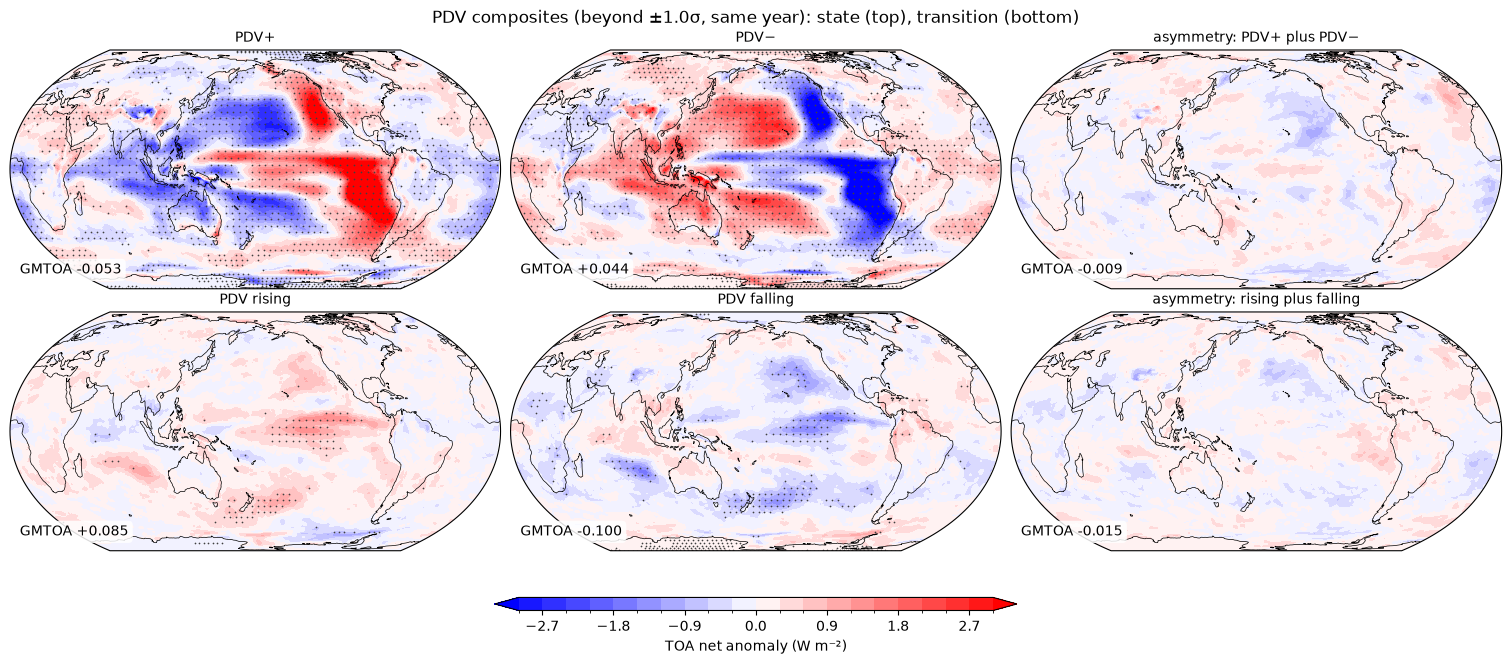

AMV composites, state: 99th percentile |value| = 1.49 W m-2, map_levels reach 3.00
AMV composites, transition: 99th percentile |value| = 1.47 W m-2, map_levels reach 3.00


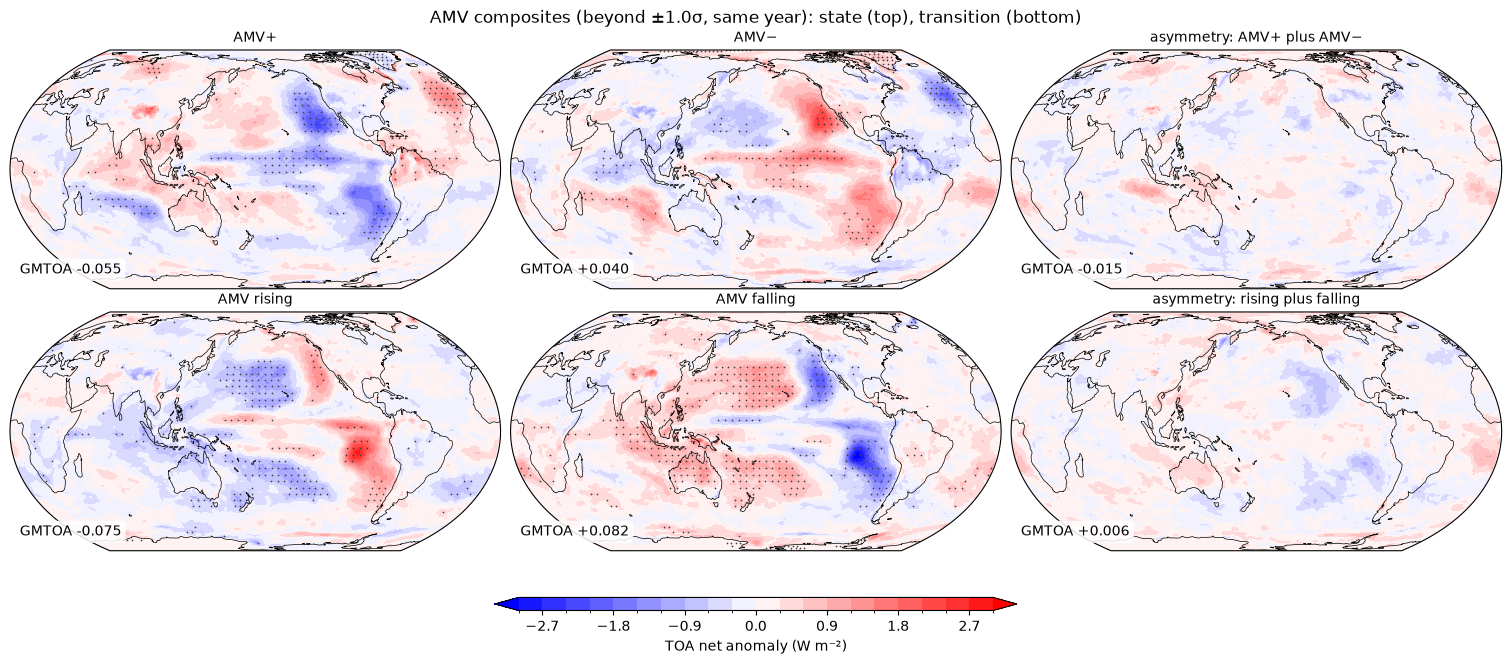

In [25]:
def composite_map(selected):
    return toa_dec.isel(time=np.flatnonzero(selected)).mean('time')


for mode in modes:
    maps = {name: composite_map(selected) for name, selected in cases[mode].items()}
    sig = {name: stipple_mask(composite_pvalues(toa32, selected))
           for name, selected in cases[mode].items()} if stippling else {}
    panels = [
        [(f'{mode}+', maps['state high'], sig.get('state high')),
         (f'{mode}−', maps['state low'], sig.get('state low')),
         (f'asymmetry: {mode}+ plus {mode}−', maps['state high'] + maps['state low'], None)],
        [(f'{mode} rising', maps['transition rising'], sig.get('transition rising')),
         (f'{mode} falling', maps['transition falling'], sig.get('transition falling')),
         ('asymmetry: rising plus falling', maps['transition rising'] + maps['transition falling'], None)],
    ]
    scale_check(f'{mode} composites, state', [da for _, da, _ in panels[0]])
    scale_check(f'{mode} composites, transition', [da for _, da, _ in panels[1]])

    fig, axes = plt.subplots(
        2, 3, figsize=(15, 6.5), subplot_kw={'projection': map_projection}, constrained_layout=True,
    )
    for row, row_panels in zip(axes, panels):
        for ax, (title, da, mask) in zip(row, row_panels):
            im = plot_map(ax, da, title, sig=mask)
    cbar = fig.colorbar(im, ax=axes, orientation='horizontal', shrink=0.35, aspect=40, pad=0.08)
    cbar.set_label('TOA net anomaly (W m⁻²)')
    fig.suptitle(f'{mode} composites (beyond ±{threshold}σ, same year): state (top), transition (bottom)')
    finish(fig, f'GMTOA_cycle_composites_{mode}')

## 6 What carries the transition signal?

| Field | Meaning | Unit |
|---|---|---|
| net, SW, LW | TOA net, absorbed solar, −OLR (all downward positive) | W m⁻² per σ |
| CLDLOW | low cloud cover, 1200–700 hPa, maximum overlap | % per σ |
| CLDHGH | high cloud cover, 400–50 hPa, maximum overlap | % per σ |
| LTS | θ(700 hPa) − θ(surface) | K per σ |

Preprocessing is the same as for TOA: annual mean → drop the first 100 years → remove the linear trend → 10-yr Lanczos low-pass. 

In [16]:
# --- config for this section ---

# one entry per panel: (levels, cmap, unit); per sigma of the rate of change.
# The figure cell prints the 99th percentile |value| per field, set the levels from that.
field_style = {
    'net':    (np.linspace(-3, 3, 21), toa_cmap, 'W m⁻²'),
    'SW':     (np.linspace(-3, 3, 21), toa_cmap, 'W m⁻²'),
    'LW':     (np.linspace(-3, 3, 21), toa_cmap, 'W m⁻²'),
    'CLDLOW': (np.linspace(-1.5, 1.5, 21), 'BrBG', '%'),
    'CLDHGH': (np.linspace(-1.5, 1.5, 21), 'BrBG', '%'),
    'LTS':    (np.linspace(-0.3, 0.3, 21), 'RdBu_r', 'K'),
}

# latitude split for the contribution to the global mean
tropics_lat = 30

In [17]:
# annual anomalies from 01_piControl_annual_anomalies.ipynb
annual = {
    'SW': read_anom('SWTOA'),
    'LW': read_anom('LWTOA'),
    'CLDLOW': read_anom('CLDLOW'),
    'CLDHGH': read_anom('CLDHGH'),
    'LTS': read_anom('LTS'),
}

# stops here if a field is on other years or another grid than the rest
xr.align(*annual.values(), join='exact')

# a grid point with any missing year would spread NaN over the filter window,
# so such points are dropped completely; then the same filter as for TOA
fields_dec = {name: lanczos_lowpass(da.where(da.notnull().all('time'))).astype('float32')
              for name, da in annual.items()}
fields_dec = {'net': toa_dec.transpose('time', 'lat', 'lon').astype('float32'), **fields_dec}

xr.align(pdv_rate, amv_rate, *fields_dec.values(), join='exact')

for name, da in annual.items():
    years = da['time'].dt.year.values
    print(f"{name:7s} {years[0]}-{years[-1]}, time mean {float(da.mean()):+.1e}, "
          f"grid points left out: {float(fields_dec[name].isel(time=0).isnull().mean()):.1%}")

SW      101-1200, time mean -1.5e-09, grid points left out: 0.0%
LW      101-1200, time mean -5.1e-10, grid points left out: 0.0%
CLDLOW  101-1200, time mean -8.1e-10, grid points left out: 5.5%
CLDHGH  101-1200, time mean -7.7e-10, grid points left out: 0.0%
LTS     101-1200, time mean +2.1e-10, grid points left out: 6.5%


In [18]:
# lag-0 regression on the rate of change
# read back if written before
saved_rate = load_result('transition_rate_maps')
names = list(fields_dec)

if saved_rate is None:
    # the autocorrelation of each field does not depend on the index, so once per field
    field_acf = {name: acf(da.values, L_metz) for name, da in fields_dec.items()}
    rate_maps, rate_p = {}, {}
    for mode, (_, rate) in modes.items():
        for name, da in fields_dec.items():
            rate_maps[mode, name] = lagged_regression(da, rate, [0]).sel(lag=0, drop=True)
            rate_p[mode, name] = regression_pvalues(da, rate, 0, acf_field=field_acf[name])
    out = xr.Dataset({
        'coef': stack({m: stack({n: rate_maps[m, n] for n in names}, 'field') for m in modes},
                      'mode').astype('float32'),
        'p': stack({m: stack({n: rate_p[m, n] for n in names}, 'field') for m in modes}, 'mode'),
    })
    save_result(out, 'transition_rate_maps')
else:
    rate_maps = {(m, n): saved_rate['coef'].sel(mode=m, field=n, drop=True) for m in modes for n in names}
    rate_p = {(m, n): saved_rate['p'].sel(mode=m, field=n, drop=True) for m in modes for n in names}

rate_sig = {key: stipple_mask(p) for key, p in rate_p.items()} if stippling else {}

read /Users/liobabraun/Desktop/Uni_Leipzig/MA/server/data/piControl/lanczos/transition_rate_maps.nc


PDV net     99th percentile |value| = 0.65 W m⁻², levels reach 3.00
PDV SW      99th percentile |value| = 0.84 W m⁻², levels reach 3.00
PDV LW      99th percentile |value| = 0.83 W m⁻², levels reach 3.00
PDV CLDLOW  99th percentile |value| = 0.41 %, levels reach 1.50
PDV CLDHGH  99th percentile |value| = 0.49 %, levels reach 1.50
PDV LTS     99th percentile |value| = 0.10 K, levels reach 0.30


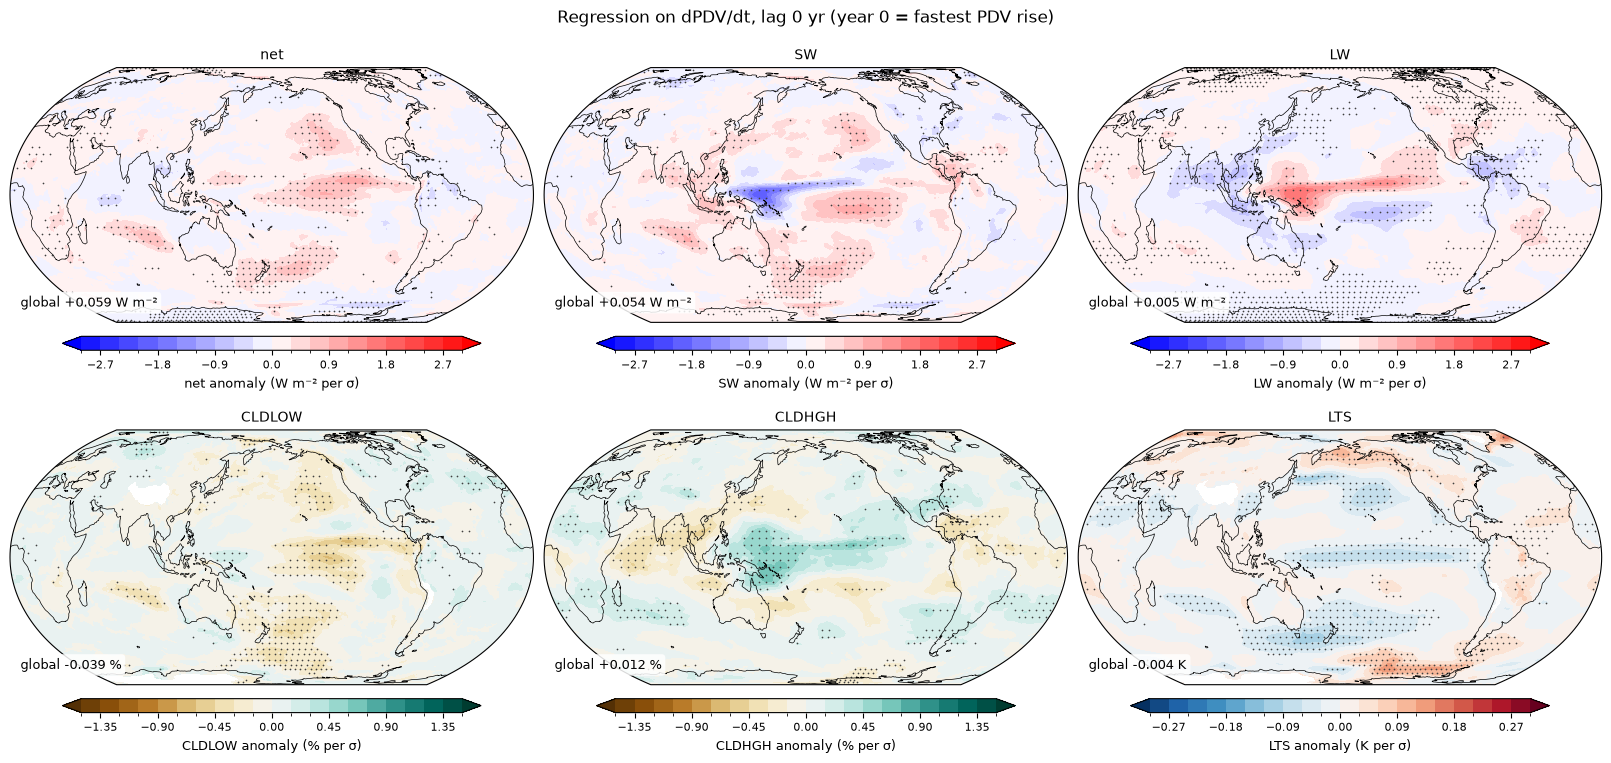

AMV net     99th percentile |value| = 0.77 W m⁻², levels reach 3.00
AMV SW      99th percentile |value| = 1.31 W m⁻², levels reach 3.00
AMV LW      99th percentile |value| = 1.19 W m⁻², levels reach 3.00
AMV CLDLOW  99th percentile |value| = 0.59 %, levels reach 1.50
AMV CLDHGH  99th percentile |value| = 0.72 %, levels reach 1.50
AMV LTS     99th percentile |value| = 0.14 K, levels reach 0.30


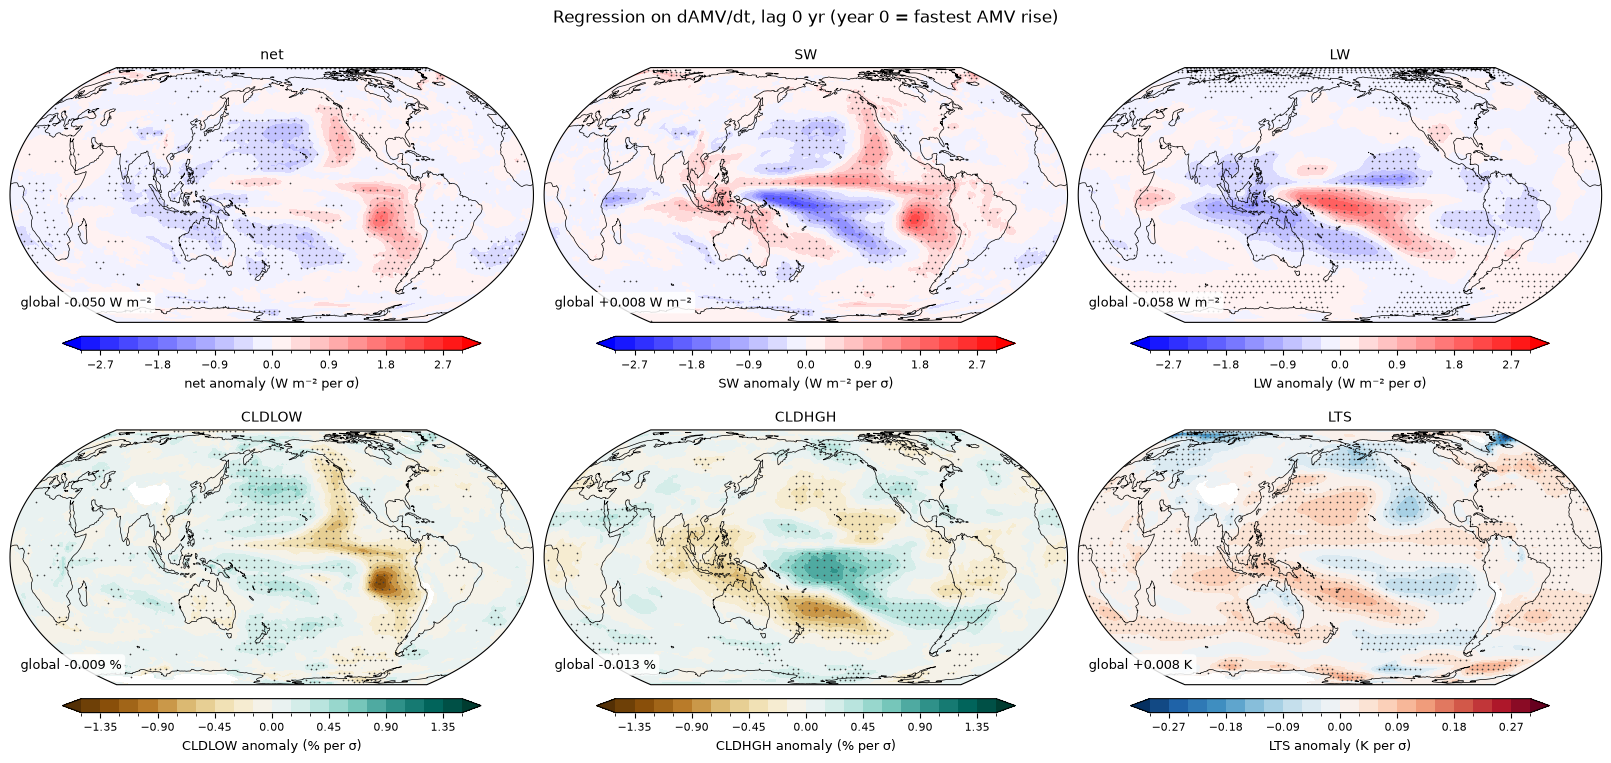

In [26]:
def plot_field(ax, da, title, levels, cmap, unit, sig=None):
    """Like plot_map, but with its own levels, colormap and unit per panel.

    plot_map always uses map_levels and toa_cmap, which only fit TOA. Stippling
    and the global mean in the corner work the same way.
    """
    im = da.plot.contourf(
        ax=ax, transform=ccrs.PlateCarree(), levels=levels, cmap=cmap,
        extend='both', add_colorbar=False, add_labels=False,
    )
    if sig is not None:
        thinned = sig.transpose('lat', 'lon').isel(
            lat=slice(stipple_step // 2, None, stipple_step),
            lon=slice(stipple_step // 2, None, stipple_step))
        lon2d, lat2d = np.meshgrid(thinned['lon'].values, thinned['lat'].values)
        ax.scatter(lon2d[thinned.values], lat2d[thinned.values], s=stipple_size,
                   color=stipple_color, linewidths=0, transform=ccrs.PlateCarree())
    ax.coastlines(linewidth=0.5)
    ax.set_global()
    if lat_limit is not None:
        _, y_limit = ax.projection.transform_point(180, lat_limit, ccrs.PlateCarree())
        ax.set_ylim(-y_limit, y_limit)
    ax.set_title(title, fontsize=10)
    ax.text(0.02, 0.05, f'global {float(global_mean(da)):+.3f} {unit}', transform=ax.transAxes,
            fontsize=9, va='bottom', ha='left',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.85, edgecolor='none'))
    return im


# top row: radiation, bottom row: clouds and stability
panel_order = [['net', 'SW', 'LW'], ['CLDLOW', 'CLDHGH', 'LTS']]

for mode in modes:
    fig, axes = plt.subplots(
        2, 3, figsize=(16, 7.5), subplot_kw={'projection': map_projection}, constrained_layout=True,
    )
    for row, names in zip(axes, panel_order):
        for ax, name in zip(row, names):
            levels, cmap, unit = field_style[name]
            da = rate_maps[mode, name]
            im = plot_field(ax, da, name, levels, cmap, unit, sig=rate_sig.get((mode, name)))
            cbar = fig.colorbar(im, ax=ax, orientation='horizontal', shrink=0.8, aspect=30, pad=0.04)
            cbar.set_label(f'{name} anomaly ({unit} per σ)', fontsize=9)
            cbar.ax.tick_params(labelsize=8)
            print(f'{mode} {name:7s} 99th percentile |value| = '
                  f'{float(np.nanpercentile(np.abs(da.values), 99)):.2f} {unit}, '
                  f'levels reach {levels[-1]:.2f}')
    fig.suptitle(f'Regression on d{mode}/dt, {lag_label(0)} (year 0 = fastest {mode} rise)')
    finish(fig, f'GMTOA_cycle_transition_clouds_{mode}')

**Contribution of latitude bands to global-mean net, SW and LW TOA radiation regressed onto PDV and AMV transition**

In [20]:
def band_contributions(da):
    """Contribution of each latitude band to the area-weighted global mean of ``da``.

    Each band's weighted sum is divided by the weight of the whole (valid) globe,
    so the parts add up to global_mean(da).
    """
    w = area_weights(da['lat']).broadcast_like(da).where(da.notnull())
    total = w.sum()
    bands = {
        f'{tropics_lat}S-{tropics_lat}N': abs(da['lat']) <= tropics_lat,
        f'north of {tropics_lat}N': da['lat'] > tropics_lat,
        f'south of {tropics_lat}S': da['lat'] < -tropics_lat,
    }
    return {band: float((da * w).where(sel).sum() / total) for band, sel in bands.items()}


rows = {}
for mode in modes:
    for name in ('net', 'SW', 'LW'):
        parts = band_contributions(rate_maps[mode, name])
        gm_value = sum(parts.values())
        row = {'global (W m-2)': gm_value}
        for band, value in parts.items():
            row[f'{band} (W m-2)'] = value
            row[f'{band} (%)'] = 100 * value / gm_value
        rows[f'd{mode}/dt  {name}'] = row

print(f'Contribution to the global mean, lag-0 regression on the rate of change (per σ)')
display(pd.DataFrame(rows).T.round(3))

Contribution to the global mean, lag-0 regression on the rate of change (per σ)


,global (W m-2),30S-30N (W m-2),30S-30N (%),north of 30N (W m-2),north of 30N (%),south of 30S (W m-2),south of 30S (%)
dPDV/dt net,0.059,0.036,60.648,0.009,14.535,0.015,24.817
dPDV/dt SW,0.054,0.038,70.093,-0.004,-6.681,0.020,36.587
dPDV/dt LW,0.005,-0.002,-39.337,0.012,239.112,-0.005,-99.775
dAMV/dt net,-0.050,-0.026,53.379,-0.012,23.516,-0.011,23.105
dAMV/dt SW,0.008,0.018,214.804,0.003,41.446,-0.013,-156.250
dAMV/dt LW,-0.058,-0.044,76.404,-0.015,26.074,0.001,-2.478
